In [3]:
# E-commerce Sales & Profitability Analysis
# Run from the project root. Install: pip install pandas numpy matplotlib seaborn jupyter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [4]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\Ecommerce_Sales_Analysis_Project\Ecommerce_Sales_Analysis_Project\data\ecommerce_sales.csv",parse_dates=["order_date", "ship_date"])
df.head()

,order_id,order_date,ship_date,customer_id,customer_segment,region,city,sales_channel,product_id,product_name,category,sub_category,quantity,unit_price,discount_pct,sales,cost,shipping_cost,profit
0,ORD00770,2024-01-01,2024-01-06,CUST0141,Consumer,West,Surat,Mobile App,P001,Wireless Mouse,Electronics,Accessories,3,690.78,0.0,2072.34,1409.19,100.65,562.50
1,ORD00231,2024-01-01,2024-01-05,CUST0024,Corporate,South,Bengaluru,Website,P010,Water Bottle,Home & Kitchen,Kitchen,1,347.85,5.0,330.46,229.58,72.33,28.55
2,ORD01056,2024-01-01,2024-01-02,CUST0249,Small Business,West,Surat,Mobile App,P007,Study Table,Furniture,Tables,6,5590.30,30.0,23479.26,26162.60,68.94,-2752.28
3,ORD00609,2024-01-02,2024-01-09,CUST0146,Consumer,West,Surat,Website,P008,Running Shoes,Fashion,Footwear,6,2431.71,30.0,10213.18,9045.96,187.09,980.13
4,ORD00718,2024-01-02,2024-01-06,CUST0049,Consumer,Central,Raipur,Website,P004,Notebook Pack,Stationery,Office Supplies,4,227.07,0.0,908.28,526.80,115.62,265.86


In [5]:
# Basic inspection
print("Shape:", df.shape)
display(df.info())
display(df.describe())
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape: (2500, 19)
<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          2500 non-null   str           
 1   order_date        2500 non-null   datetime64[us]
 2   ship_date         2500 non-null   datetime64[us]
 3   customer_id       2500 non-null   str           
 4   customer_segment  2500 non-null   str           
 5   region            2500 non-null   str           
 6   city              2500 non-null   str           
 7   sales_channel     2500 non-null   str           
 8   product_id        2500 non-null   str           
 9   product_name      2500 non-null   str           
 10  category          2500 non-null   str           
 11  sub_category      2500 non-null   str           
 12  quantity          2500 non-null   int64         
 13  unit_price        2500 non-null   float64       
 14  discount_pct     

None

,order_date,ship_date,quantity,unit_price,discount_pct,sales,cost,shipping_cost,profit
count,2500,2500,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,2024-12-29 05:15:04.320000,2025-01-02 06:51:50.400000,2.382400,2305.385380,10.536000,4865.285728,3915.778172,100.377532,849.129928
min,2024-01-01 00:00:00,2024-01-02 00:00:00,1.000000,193.790000,0.000000,129.810000,112.800000,20.080000,-5642.680000
25%,2024-06-30 18:00:00,2024-07-06 00:00:00,1.000000,517.412500,0.000000,1016.145000,749.632500,62.870000,117.572500
50%,2024-12-24 00:00:00,2024-12-28 00:00:00,2.000000,1372.560000,10.000000,2537.785000,1869.865000,98.125000,418.700000
75%,2025-06-28 00:00:00,2025-07-02 00:00:00,3.000000,3816.762500,20.000000,6395.582500,5111.097500,132.275000,1184.940000
max,2025-12-31 00:00:00,2026-01-06 00:00:00,6.000000,8062.010000,35.000000,41685.620000,36127.540000,232.260000,8717.960000
std,NaN,NaN,1.376128,2116.251881,9.631709,5870.629543,5048.377082,45.569374,1211.971893


order_id            0
order_date          0
ship_date           0
customer_id         0
customer_segment    0
region              0
city                0
sales_channel       0
product_id          0
product_name        0
category            0
sub_category        0
quantity            0
unit_price          0
discount_pct        0
sales               0
cost                0
shipping_cost       0
profit              0
dtype: int64

Duplicate rows: 0


In [6]:
# Data quality checks
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["ship_date"] = pd.to_datetime(df["ship_date"], errors="coerce")
df = df.drop_duplicates()
df = df.dropna(subset=["order_id", "order_date", "customer_id", "product_id"])
df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days
df["profit_margin_pct"] = np.where(df["sales"] != 0, df["profit"] / df["sales"] * 100, np.nan)
df["order_month"] = df["order_date"].dt.to_period("M").astype(str)

In [7]:
# Reconcile core metrics
kpis = pd.DataFrame({
    "Metric": ["Revenue", "Profit", "Profit Margin %", "Orders", "Customers", "Units Sold", "AOV"],
    "Value": [
        df["sales"].sum(),
        df["profit"].sum(),
        df["profit"].sum()/df["sales"].sum()*100,
        df["order_id"].nunique(), 
        df["customer_id"].nunique(),
        df["quantity"].sum(),
        df["sales"].sum()/df["order_id"].nunique()
    ]
})
display(kpis)

,Metric,Value
0,Revenue,1.216321e+07
1,Profit,2.122825e+06
2,Profit Margin %,1.745283e+01
3,Orders,1.250000e+03
4,Customers,4.000000e+02
5,Units Sold,5.956000e+03
6,AOV,9.730571e+03


,order_month,revenue,profit,mom_growth_pct
12,2025-01,615943.89,95546.46,29.325316
13,2025-02,508215.59,81068.15,-17.489954
14,2025-03,496091.88,91651.56,-2.385545
15,2025-04,564847.17,94047.89,13.859386
16,2025-05,557670.82,105721.69,-1.270494
17,2025-06,493082.91,76263.86,-11.581727
18,2025-07,544818.27,93899.12,10.492223
19,2025-08,397333.86,64745.05,-27.070386
20,2025-09,553159.87,86613.03,39.217904
21,2025-10,536431.32,92753.43,-3.024180


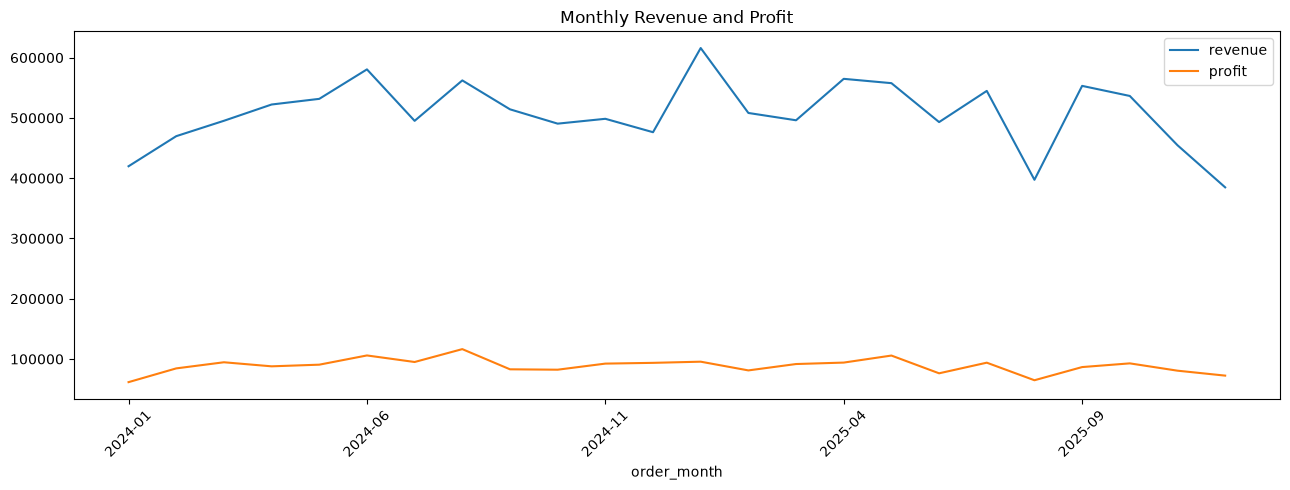

In [8]:
# Monthly trend
monthly = df.groupby("order_month", as_index=False).agg(revenue=("sales","sum"), profit=("profit","sum"))
monthly["mom_growth_pct"] = monthly["revenue"].pct_change()*100
display(monthly.tail(12))
monthly.plot(x="order_month", y=["revenue","profit"], figsize=(13,5), title="Monthly Revenue and Profit")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

,category,revenue,profit,margin_pct
2,Furniture,6063325.09,699624.81,11.538633
0,Electronics,2885278.64,612960.94,21.244428
3,Home & Kitchen,1535435.76,357554.65,23.286852
1,Fashion,1294159.95,363888.02,28.117701
4,Stationery,385014.88,88796.40,23.063109


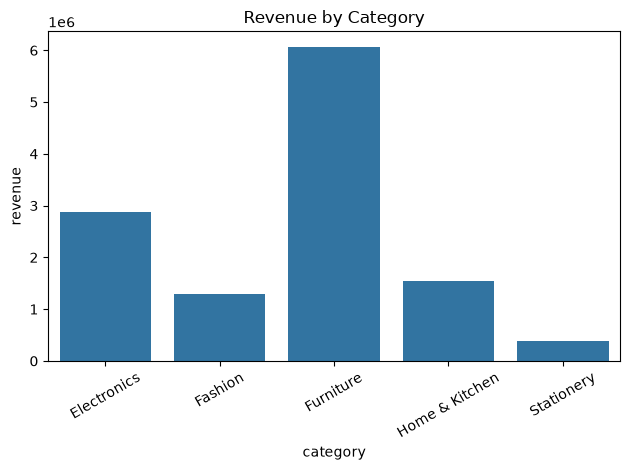

,region,revenue,profit,margin_pct
0,Central,2794724.50,491154.79,17.574354
3,South,2309585.17,427310.12,18.501596
2,North,2223647.83,408655.75,18.377719
4,West,2519780.37,408148.59,16.197784
1,East,2315476.45,387555.57,16.737617


In [9]:
# Category and regional performance
category = df.groupby("category", as_index=False).agg(revenue=("sales","sum"), profit=("profit","sum"))
category["margin_pct"] = category["profit"]/category["revenue"]*100
display(category.sort_values("revenue",ascending=False))
sns.barplot(data=category, x="category", y="revenue")
plt.xticks(rotation=30); plt.title("Revenue by Category"); plt.tight_layout(); plt.show()

region = df.groupby("region", as_index=False).agg(revenue=("sales","sum"), profit=("profit","sum"))
region["margin_pct"] = region["profit"]/region["revenue"]*100
display(region.sort_values("profit",ascending=False))

In [10]:
# Product profitability: find products with negative total profit
product = df.groupby(["product_name","category"], as_index=False).agg(
    revenue=("sales","sum"), profit=("profit","sum"), units=("quantity","sum"))
display(product.sort_values("profit").head(10))

,product_name,category,revenue,profit,units
6,Notebook Pack,Stationery,84373.26,11350.94,438
13,Water Bottle,Home & Kitchen,118357.65,16018.63,383
8,Printer Paper,Stationery,138260.28,34748.71,388
14,Wireless Mouse,Electronics,248084.14,41019.31,429
4,Desk Organizer,Stationery,162381.34,42696.75,377
5,LED Desk Lamp,Home & Kitchen,355062.51,79048.29,412
12,USB-C Hub,Electronics,458770.87,97934.57,404
0,Backpack,Fashion,441995.80,119812.64,367
1,Bluetooth Speaker,Electronics,621556.73,130075.99,387
2,Bookshelf,Furniture,1358005.34,165927.78,369


In [11]:
# Discount analysis
df["discount_band"] = pd.cut(
    df["discount_pct"], bins=[-0.01,0,10,20,100],
    labels=["0%","1-10%","11-20%",">20%"]
)
discount = df.groupby("discount_band", observed=False, as_index=False).agg(
    revenue=("sales","sum"), profit=("profit","sum"), line_items=("order_id","size"))
discount["margin_pct"] = discount["profit"]/discount["revenue"]*100
display(discount)

,discount_band,revenue,profit,line_items,margin_pct
0,0%,3972211.25,1047344.29,758,26.366782
1,1-10%,4081224.30,817934.11,806,20.041391
2,11-20%,2825137.48,296298.34,614,10.487926
3,>20%,1284641.29,-38751.92,322,-3.016556


In [12]:
# Customer analysis
customer = df.groupby("customer_id", as_index=False).agg(
    revenue=("sales","sum"), profit=("profit","sum"), orders=("order_id","nunique"))
display(customer.sort_values("revenue",ascending=False).head(10))

,customer_id,revenue,profit,orders
139,CUST0140,103564.66,19598.12,12
80,CUST0081,98695.66,19327.01,7
306,CUST0307,84409.85,16312.66,9
9,CUST0010,83643.51,20423.43,14
234,CUST0235,82502.53,18929.11,9
25,CUST0026,80751.71,11800.42,10
171,CUST0172,79035.30,6335.99,9
28,CUST0029,78994.81,11093.93,9
370,CUST0371,77630.02,11215.59,6
293,CUST0294,75436.84,16267.37,10


In [14]:
# Export a cleaned file for Power BI
df.to_csv("ecommerce_sales_cleaned.csv", index=False)

print("Cleaned data saved successfully!")

Cleaned data saved successfully!
